# Scenario - 3 Past Power + Past Exogenous inputs + Future Exogenous variables

Imports, paths, artifact locations, and configuration variables are defined in the next cell.

In [2]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model


# 2. Load Dataset

Load the existing chronological Excel datasets and inspect their row/day counts. No raw data or split files are changed.

In [3]:
from pathlib import Path
import pandas as pd

SEASON = "Summer"
SCENARIO = "S3"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
DATA_DIR = (
    PROJECT_DIR
    / "OneDrive_2026-08-26"
    / "Solar Profile Dataset"
    / SEASON
)

TRAIN_PATH = DATA_DIR / "Summer_Train.xlsx"
VALIDATION_PATH = DATA_DIR / "Summer_Val.xlsx"
TEST_PATH = DATA_DIR / "Summer_Test.xlsx"

TEST_START = pd.Timestamp("2026-06-08")
TEST_END_EXCLUSIVE = pd.Timestamp("2026-06-15")
HISTORY_DAY = TEST_START - pd.Timedelta(days=1)


def load_data(train_path, validation_path, test_path):
    """Load and sort the existing summer splits."""
    splits = []

    for path in (train_path, validation_path, test_path):
        data = pd.read_excel(path)
        data["TimeStamp"] = pd.to_datetime(
            data["TimeStamp"], errors="raise"
        )

        if data["TimeStamp"].isna().any():
            raise ValueError(f"{path.name}: missing timestamps.")

        if data["TimeStamp"].duplicated().any():
            raise ValueError(f"{path.name}: duplicate timestamps.")

        data = data.sort_values("TimeStamp").reset_index(drop=True)
        data["Date"] = data["TimeStamp"].dt.date
        splits.append(data)

    return tuple(splits)


def check_split(data, name, first_day, last_day):
    """Require a complete, unique 15-minute block-start grid."""
    expected = pd.date_range(
        start=first_day,
        end=pd.Timestamp(last_day) + pd.Timedelta(hours=23, minutes=45),
        freq="15min",
    )
    observed = pd.DatetimeIndex(data["TimeStamp"])

    if not observed.equals(expected):
        raise ValueError(
            f"{name}: expected a complete 15-minute grid "
            f"from {first_day} through {last_day}. "
            f"Found {len(observed)} rows; expected {len(expected)}."
        )

    print(
        f"{name}: {data['Date'].nunique()} days | "
        f"{len(data)} rows | {observed[0]} → {observed[-1]}"
    )


train, validation, original_test = load_data(
    TRAIN_PATH,
    VALIDATION_PATH,
    TEST_PATH,
)

# Validation already extends through June 7.
check_split(train, "Training", "2026-02-15", "2026-05-09")
check_split(validation, "Validation", "2026-05-10", "2026-06-07")

# Exactly seven test target days.
test = original_test.loc[
    original_test["TimeStamp"].ge(TEST_START)
    & original_test["TimeStamp"].lt(TEST_END_EXCLUSIVE)
].copy().reset_index(drop=True)

check_split(test, "Test targets", "2026-06-08", "2026-06-14")

if set(validation.columns) != set(test.columns):
    raise ValueError("Validation and test column names differ.")

# June 7 supplies historical inputs for the June 8 forecast.
history_rows = validation.loc[
    validation["Date"] == HISTORY_DAY.date()
].copy()

test_with_history = pd.concat(
    [history_rows, test],
    ignore_index=True,
).sort_values("TimeStamp", ignore_index=True)

check_split(
    test_with_history,
    "Test including history",
    "2026-06-07",
    "2026-06-14",
)

print("\nSummer S3 expected samples:")
print("Training   : 332")
print("Validation : 112")
print("Test       : 28")
print("\nUse test_with_history for test sample creation.")

Training: 84 days | 8064 rows | 2026-02-15 00:00:00 → 2026-05-09 23:45:00
Validation: 29 days | 2784 rows | 2026-05-10 00:00:00 → 2026-06-07 23:45:00
Test targets: 7 days | 672 rows | 2026-06-08 00:00:00 → 2026-06-14 23:45:00
Test including history: 8 days | 768 rows | 2026-06-07 00:00:00 → 2026-06-14 23:45:00

Summer S3 expected samples:
Training   : 332
Validation : 112
Test       : 28

Use test_with_history for test sample creation.


# 3. Train / Validation / Test Split

The notebook uses the existing chronological Excel splits without re-splitting or shuffling the datasets.

# 4. Revision Sample Creation

Put the existing revision lengths, target length, padded input length, sample creator, and train/validation/test sample creation in this section.

In [4]:
import numpy as np
import pandas as pd

REVISION_LENGTHS = {
    "R0": 32,
    "R1": 50,
    "R2": 64,
    "R3": 82,
}

TARGET_LENGTH = 96
BLOCKS_PER_DAY = 96
PADDED_INPUT_LENGTH = 82
POWER_COLUMN = "Act. Power (MW)"
MASK_VALUE = -1.0
PAD_VALUE = MASK_VALUE

# Preserve the historical feature order from Winter S3.
PAST_EXOG_COLUMNS = [
    "W-MODT- (°C)",
    "W-GHI (W/m2)",
    "W-AMBT (°C)",
    "W-WDIR-   (Degree)",
]
HISTORY_COLUMNS = [POWER_COLUMN] + PAST_EXOG_COLUMNS

# Fixed selected future features; no new feature search.
SELECTED_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
]
FUTURE_EXOG_COLUMNS = SELECTED_FUTURE_EXOG_COLUMNS.copy()

# Clock features are added in preprocessing.
N_HISTORY_FEATURES = len(HISTORY_COLUMNS) + 2
N_FUTURE_EXOG = len(FUTURE_EXOG_COLUMNS)

if POWER_COLUMN in FUTURE_EXOG_COLUMNS:
    raise ValueError("Future actual power cannot be an input feature.")


def normalize_header(name):
    return " ".join(str(name).split())


def resolve_columns(data, names):
    lookup = {}

    for column in data.columns:
        key = normalize_header(column)
        if key in lookup:
            raise ValueError(f"Ambiguous column headers: {key}")
        lookup[key] = column

    missing = [
        name for name in names
        if normalize_header(name) not in lookup
    ]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    return [lookup[normalize_header(name)] for name in names]


def create_revision_samples(split, split_name="Split"):
    """Create unscaled D → D+1 histories, future weather, and targets."""
    data = split.copy()
    data["TimeStamp"] = pd.to_datetime(
        data["TimeStamp"], errors="raise"
    )
    data = data.sort_values("TimeStamp").reset_index(drop=True)

    timestamps = data["TimeStamp"]
    if timestamps.isna().any() or timestamps.duplicated().any():
        raise ValueError(f"{split_name}: missing or duplicate timestamps.")

    if not timestamps.eq(timestamps.dt.floor("15min")).all():
        raise ValueError(f"{split_name}: timestamps are off the 15-minute grid.")

    data["Date"] = timestamps.dt.date

    history_cols = resolve_columns(data, HISTORY_COLUMNS)
    future_cols = resolve_columns(data, FUTURE_EXOG_COLUMNS)
    power_col = resolve_columns(data, [POWER_COLUMN])[0]

    for column in dict.fromkeys(history_cols + future_cols):
        data[column] = pd.to_numeric(data[column], errors="raise")

    day_groups = {
        day: rows.set_index("TimeStamp")
        for day, rows in data.groupby("Date", sort=True)
    }

    X, X_future, y = [], [], []
    revision_labels, sample_dates = [], []
    revision_indices = {
        revision: [] for revision in REVISION_LENGTHS
    }

    for day, day_data in day_groups.items():
        next_day = (pd.Timestamp(day) + pd.Timedelta(days=1)).date()
        target_data = day_groups.get(next_day)

        if target_data is None:
            continue

        history_grid = pd.date_range(
            day, periods=PADDED_INPUT_LENGTH, freq="15min"
        )
        target_grid = pd.date_range(
            next_day, periods=TARGET_LENGTH, freq="15min"
        )

        if not history_grid.isin(day_data.index).all():
            raise ValueError(f"{split_name}: incomplete history on {day}.")

        if not target_data.index.equals(target_grid):
            raise ValueError(
                f"{split_name}: incomplete target day {next_day}."
            )

        history = day_data.loc[
            history_grid, history_cols
        ].to_numpy(dtype=np.float32)

        future_exog = target_data.loc[
            target_grid, future_cols
        ].to_numpy(dtype=np.float32)

        target = target_data.loc[
            target_grid, power_col
        ].to_numpy(dtype=np.float32)

        for name, values in (
            ("history", history),
            ("future weather", future_exog),
            ("target power", target),
        ):
            if not np.isfinite(values).all():
                raise ValueError(
                    f"{split_name}: nonfinite {name} in {day} → {next_day}."
                )

        for revision, length in REVISION_LENGTHS.items():
            revision_indices[revision].append(len(X))
            X.append(history[:length].copy())
            X_future.append(future_exog.copy())
            y.append(target.copy())
            revision_labels.append(revision)
            sample_dates.append(next_day)

    if not X:
        raise ValueError(f"{split_name}: no consecutive-day samples.")

    return (
        X,
        np.stack(X_future),
        np.stack(y),
        np.asarray(revision_labels),
        revision_indices,
        np.asarray(sample_dates),
    )


(
    X_train,
    X_future_train,
    y_train,
    revision_labels_train,
    revision_indices_train,
    dates_train,
) = create_revision_samples(train, "Train")

(
    X_validation,
    X_future_validation,
    y_validation,
    revision_labels_validation,
    revision_indices_validation,
    dates_validation,
) = create_revision_samples(validation, "Validation")

# Already contains June 7 history plus June 8–14 targets.
(
    X_test,
    X_future_test,
    y_test,
    revision_labels_test,
    revision_indices_test,
    dates_test,
) = create_revision_samples(test_with_history, "Test")


# Verify all target dates and revisions, including duplicate detection.
expected_ranges = {
    "Train": ("2026-02-16", "2026-05-09"),
    "Validation": ("2026-05-11", "2026-06-07"),
    "Test": ("2026-06-08", "2026-06-14"),
}

for name, histories, future, targets, labels, dates in (
    (
        "Train", X_train, X_future_train, y_train,
        revision_labels_train, dates_train,
    ),
    (
        "Validation", X_validation, X_future_validation, y_validation,
        revision_labels_validation, dates_validation,
    ),
    (
        "Test", X_test, X_future_test, y_test,
        revision_labels_test, dates_test,
    ),
):
    first_day, last_day = expected_ranges[name]
    expected_days = pd.date_range(first_day, last_day, freq="D")

    expected_pairs = pd.MultiIndex.from_product(
        [expected_days.date, list(REVISION_LENGTHS)]
    )
    actual_pairs = pd.MultiIndex.from_arrays([dates, labels])

    if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
        raise ValueError(f"{name}: unexpected target dates or revisions.")

    n_samples = len(expected_pairs)

    assert len(histories) == n_samples
    assert targets.shape == (n_samples, TARGET_LENGTH)
    assert future.shape == (
        n_samples, TARGET_LENGTH, len(FUTURE_EXOG_COLUMNS)
    )
    assert all(
        history.shape == (REVISION_LENGTHS[revision], len(HISTORY_COLUMNS))
        for history, revision in zip(histories, labels)
    )

    print(
        f"{name}: {len(expected_days)} target days | "
        f"{n_samples} samples"
    )
    print(f"  Raw history shapes: {[x.shape for x in histories[:4]]}")
    print(f"  Future weather: {future.shape}")
    print(f"  Targets: {targets.shape}")


target_date_sets = [
    set(dates_train),
    set(dates_validation),
    set(dates_test),
]
if any(
    target_date_sets[i] & target_date_sets[j]
    for i, j in ((0, 1), (0, 2), (1, 2))
):
    raise ValueError("Target dates overlap across splits.")

revision_info = {
    "lengths": REVISION_LENGTHS.copy(),
    "train": revision_indices_train,
    "validation": revision_indices_validation,
    "test": revision_indices_test,
}

test_dates = sorted(set(dates_test))


# Night-mask source: ALL complete raw summer training days.
# Includes the first training day, which does not appear in y_train.
training_data = train.copy()
training_data["TimeStamp"] = pd.to_datetime(
    training_data["TimeStamp"], errors="raise"
)
training_data = training_data.sort_values("TimeStamp")
training_power_col = resolve_columns(
    training_data, [POWER_COLUMN]
)[0]

complete_training_days = []

for day, rows in training_data.groupby(
    training_data["TimeStamp"].dt.normalize(), sort=True
):
    expected_grid = pd.date_range(
        day, periods=BLOCKS_PER_DAY, freq="15min"
    )

    if not pd.DatetimeIndex(rows["TimeStamp"]).equals(expected_grid):
        raise ValueError(f"Incomplete training day for night mask: {day.date()}")

    power = pd.to_numeric(
        rows[training_power_col], errors="raise"
    ).to_numpy(dtype=np.float32)

    if not np.isfinite(power).all():
        raise ValueError(f"Nonfinite training power on {day.date()}.")

    complete_training_days.append(power)

if not complete_training_days:
    raise ValueError("No complete training days for the night mask.")

nightmask_training_power = np.stack(complete_training_days)
active_fraction = (nightmask_training_power > 0.1).mean(axis=0)
night_mask = active_fraction < 0.10
night_blocks = np.flatnonzero(night_mask)

print("\nHistorical measurements:", HISTORY_COLUMNS)
print("Selected future weather:", FUTURE_EXOG_COLUMNS)
print("Night-mask source:", nightmask_training_power.shape)
print("Test: 7 target days × 4 revisions = 28 samples")

Train: 83 target days | 332 samples
  Raw history shapes: [(32, 5), (50, 5), (64, 5), (82, 5)]
  Future weather: (332, 96, 3)
  Targets: (332, 96)
Validation: 28 target days | 112 samples
  Raw history shapes: [(32, 5), (50, 5), (64, 5), (82, 5)]
  Future weather: (112, 96, 3)
  Targets: (112, 96)
Test: 7 target days | 28 samples
  Raw history shapes: [(32, 5), (50, 5), (64, 5), (82, 5)]
  Future weather: (28, 96, 3)
  Targets: (28, 96)

Historical measurements: ['Act. Power (MW)', 'W-MODT- (°C)', 'W-GHI (W/m2)', 'W-AMBT (°C)', 'W-WDIR-   (Degree)']
Selected future weather: ['W-GHI (W/m2)', 'W-WDIR-   (Degree)', 'W-WSPD (m/s)']
Night-mask source: (84, 96)
Test: 7 target days × 4 revisions = 28 samples


# 5. Preprocessing and Scaling

This section preserves the existing `MinMaxScaler`, time features, padding, and scaled input creation.

In [5]:
from sklearn.preprocessing import MinMaxScaler

# Resolve extra spaces in Excel column headers.
def get_feature_values(df, columns):
    normalize = lambda name: ' '.join(str(name).split())
    lookup = {normalize(col): col for col in df.columns}
    actual_columns = [lookup[normalize(col)] for col in columns]
    return df[actual_columns].to_numpy(dtype=np.float32)


# Separate scalers for target power, past exogenous, and future exogenous.
# Keep the name "scaler" for compatibility with inverse-scaling later.
scaler = MinMaxScaler()
past_exog_scaler = MinMaxScaler()
future_exog_scaler = MinMaxScaler()

scaler.fit(get_feature_values(train, [POWER_COLUMN]))
past_exog_scaler.fit(get_feature_values(train, PAST_EXOG_COLUMNS))
future_exog_scaler.fit(get_feature_values(train, FUTURE_EXOG_COLUMNS))

train_power_scaled = scaler.transform(
    get_feature_values(train, [POWER_COLUMN])
)
val_power_scaled = scaler.transform(
    get_feature_values(validation, [POWER_COLUMN])
)
test_power_scaled = scaler.transform(
    get_feature_values(test, [POWER_COLUMN])
)


def time_features(block_indices):
    block_indices = np.asarray(block_indices, dtype=np.float32)
    phase = 2.0 * np.pi * block_indices / BLOCKS_PER_DAY
    return np.column_stack(
        (np.sin(phase), np.cos(phase))
    ).astype(np.float32)


N_HISTORY_FEATURES = 1 + len(PAST_EXOG_COLUMNS) + 2
N_FUTURE_FEATURES = len(FUTURE_EXOG_COLUMNS) + 2


def preprocess_revision_samples(
    X_raw, X_future_raw, y_raw, revision_labels
):
    n_samples = len(X_raw)

    assert len(revision_labels) == n_samples
    assert y_raw.shape == (n_samples, TARGET_LENGTH)
    assert X_future_raw.shape == (
        n_samples, TARGET_LENGTH, len(FUTURE_EXOG_COLUMNS)
    )

    # Every channel in padded timesteps must equal MASK_VALUE.
    X_processed = np.full(
        (n_samples, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        MASK_VALUE,
        dtype=np.float32,
    )

    # Scale real history first, then insert into padded array.
    for i, (history, revision) in enumerate(
        zip(X_raw, revision_labels)
    ):
        real_length = REVISION_LENGTHS[revision]

        assert history.shape == (
            real_length, 1 + len(PAST_EXOG_COLUMNS)
        )

        scaled_power = scaler.transform(history[:, :1])
        scaled_exog = past_exog_scaler.transform(history[:, 1:])
        temporal = time_features(np.arange(real_length))

        X_processed[i, :real_length] = np.concatenate(
            [scaled_power, scaled_exog, temporal],
            axis=-1,
        ).astype(np.float32)

    # Future inputs cover the full target day; no padding.
    future_scaled = future_exog_scaler.transform(
        X_future_raw.reshape(-1, len(FUTURE_EXOG_COLUMNS))
    ).reshape(
        n_samples, TARGET_LENGTH, len(FUTURE_EXOG_COLUMNS)
    ).astype(np.float32)

    future_time = np.broadcast_to(
        time_features(np.arange(TARGET_LENGTH))[None, :, :],
        (n_samples, TARGET_LENGTH, 2),
    )

    X_future_processed = np.concatenate(
        [future_scaled, future_time],
        axis=-1,
    ).astype(np.float32)

    y_scaled = scaler.transform(
        y_raw.reshape(-1, 1)
    ).reshape(y_raw.shape).astype(np.float32)

    return X_processed, X_future_processed, y_scaled


(
    X_train_scaled, X_future_train_scaled, y_train_scaled
) = preprocess_revision_samples(
    X_train, X_future_train, y_train, revision_labels_train
)

(
    X_validation_scaled, X_future_validation_scaled,
    y_validation_scaled
) = preprocess_revision_samples(
    X_validation, X_future_validation, y_validation,
    revision_labels_validation,
)

(
    X_test_scaled, X_future_test_scaled, y_test_scaled
) = preprocess_revision_samples(
    X_test, X_future_test, y_test, revision_labels_test
)


# Validate shapes, padding, and temporal alignment.
for split_name, X_scaled, future_scaled, y_scaled, labels in (
    (
        'Train', X_train_scaled, X_future_train_scaled,
        y_train_scaled, revision_labels_train,
    ),
    (
        'Validation', X_validation_scaled, X_future_validation_scaled,
        y_validation_scaled, revision_labels_validation,
    ),
    (
        'Test', X_test_scaled, X_future_test_scaled,
        y_test_scaled, revision_labels_test,
    ),
):
    assert X_scaled.shape == (
        len(labels), PADDED_INPUT_LENGTH, N_HISTORY_FEATURES
    )
    assert future_scaled.shape == (
        len(labels), TARGET_LENGTH, N_FUTURE_FEATURES
    )
    assert y_scaled.shape == (len(labels), TARGET_LENGTH)

    assert np.isfinite(X_scaled).all()
    assert np.isfinite(future_scaled).all()
    assert np.isfinite(y_scaled).all()

    assert np.allclose(
        future_scaled[:, :, -2:],
        time_features(np.arange(TARGET_LENGTH))[None, :, :],
    )

    for revision, real_length in REVISION_LENGTHS.items():
        revision_mask = labels == revision
        if not revision_mask.any():
            continue

        real = X_scaled[revision_mask, :real_length, :]
        padding = X_scaled[revision_mask, real_length:, :]

        assert np.all(padding == MASK_VALUE)
        assert not np.any(np.all(real == MASK_VALUE, axis=-1))
        assert np.allclose(
            real[:, :, -2:],
            time_features(np.arange(real_length))[None, :, :],
        )

    print(
        f'{split_name}: history={X_scaled.shape}, '
        f'future={future_scaled.shape}, target={y_scaled.shape}'
    )

# Keep nightmask_training_power in original MW.
# Do not mask targets or future weather inputs in this cell.
print('Preprocessing checks passed.')

Train: history=(332, 82, 7), future=(332, 96, 5), target=(332, 96)
Validation: history=(112, 82, 7), future=(112, 96, 5), target=(112, 96)
Test: history=(28, 82, 7), future=(28, 96, 5), target=(28, 96)
Preprocessing checks passed.


# 6. Reproducibility

This section must run before model creation or training.REPRODUCIBLITY

In [6]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")

Reproducibility configured with seed 42.


# 7. Model Architecture

This section contains only the existing encoder-decoder model definition.

In [7]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Masking, SimpleRNN, Dense, Concatenate,
    RepeatVector, TimeDistributed, Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping


def build_model(n_future_exog):
    """
    n_future_exog: number of future weather variables being tested.
    Two time channels are always included.
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_input = Input(
        shape=(PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        name='encoder_input',
    )

    masked_encoder_input = Masking(
        mask_value=MASK_VALUE,
        name='encoder_masking',
    )(encoder_input)

    encoder_context = SimpleRNN(
        64,
        name='encoder_rnn',
    )(masked_encoder_input)

    future_input = Input(
        shape=(TARGET_LENGTH, n_future_exog + 2),
        name='future_input',
    )

    repeated_context = RepeatVector(
        TARGET_LENGTH,
        name='repeat_context',
    )(encoder_context)

    decoder_input = Concatenate(
        axis=-1,
        name='decoder_features',
    )([repeated_context, future_input])

    decoder_sequence = SimpleRNN(
        64,
        return_sequences=True,
        name='decoder_rnn',
    )(decoder_input)

    block_predictions = TimeDistributed(
        Dense(1),
        name='block_prediction',
    )(decoder_sequence)

    forecast = Reshape(
        (TARGET_LENGTH,),
        name='forecast',
    )(block_predictions)

    model = Model(
        inputs=[encoder_input, future_input],
        outputs=forecast,
    )

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae'],
    )

    assert model.input_shape == [
        (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        (None, TARGET_LENGTH, n_future_exog + 2),
    ]
    assert model.output_shape == (None, TARGET_LENGTH)

    return model


print("Model builder ready for future-feature selection.")

Model builder ready for future-feature selection.


# 8. Model Training

**RUN ONLY WHEN TRAINING THE MODEL**  
**DO NOT RUN FOR DEMO**

In [8]:
from pathlib import Path
from time import perf_counter
from datetime import datetime
import platform

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping


# 1. Summer S3 configuration
SEASON = "Summer"
SCENARIO = "S3"
SEED = 42
BATCH_SIZE = 16
MAX_EPOCHS = 150

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
timing_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Timing"
)
timing_dir.mkdir(parents=True, exist_ok=True)

SELECTED_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
]

source_columns = list(FUTURE_EXOG_COLUMNS)

missing = set(SELECTED_FUTURE_EXOG_COLUMNS) - set(source_columns)
if missing:
    raise ValueError(f"Missing future weather columns: {sorted(missing)}")

selected_indices = [
    source_columns.index(column)
    for column in SELECTED_FUTURE_EXOG_COLUMNS
] + [len(source_columns), len(source_columns) + 1]


# 2. Prepare selected weather inputs followed by sin/cos time.
def select_s3_future(full_inputs):
    full_inputs = np.asarray(full_inputs)

    if (
        full_inputs.ndim != 3
        or full_inputs.shape[1:] != (
            TARGET_LENGTH, len(source_columns) + 2
        )
    ):
        raise ValueError(
            f"Unexpected future input shape: {full_inputs.shape}"
        )

    return full_inputs[:, :, selected_indices].astype(np.float32)


benchmark_future_train = select_s3_future(X_future_train_scaled)
benchmark_future_validation = select_s3_future(
    X_future_validation_scaled
)
benchmark_future_test = select_s3_future(X_future_test_scaled)

# Compatibility with later S3 prediction cells.
X_future_train_selected = benchmark_future_train
X_future_validation_selected = benchmark_future_validation
X_future_test_selected = benchmark_future_test

for name, X, future, y, expected_samples in (
    (
        "Train",
        X_train_scaled,
        benchmark_future_train,
        y_train_scaled,
        332,
    ),
    (
        "Validation",
        X_validation_scaled,
        benchmark_future_validation,
        y_validation_scaled,
        112,
    ),
    (
        "Test",
        X_test_scaled,
        benchmark_future_test,
        y_test_scaled,
        28,
    ),
):
    if X.shape != (expected_samples, PADDED_INPUT_LENGTH, 7):
        raise ValueError(f"{name}: unexpected history shape {X.shape}.")

    if future.shape != (expected_samples, TARGET_LENGTH, 5):
        raise ValueError(f"{name}: unexpected future shape {future.shape}.")

    if y.shape != (expected_samples, TARGET_LENGTH):
        raise ValueError(f"{name}: unexpected target shape {y.shape}.")

    if not all(np.isfinite(values).all() for values in (X, future, y)):
        raise ValueError(f"{name}: missing or infinite values.")


test_days = pd.date_range("2026-06-08", "2026-06-14", freq="D")
expected_pairs = pd.MultiIndex.from_product(
    [test_days, list(REVISION_LENGTHS)]
)
actual_pairs = pd.MultiIndex.from_arrays([
    pd.DatetimeIndex(pd.to_datetime(dates_test)).normalize(),
    revision_labels_test,
])

if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError("Expected all four revisions for June 8–14.")


# 3. Fresh benchmark model using the shared architecture.
# Running this cell again starts a new training run.
benchmark_model = build_model(
    n_future_exog=len(SELECTED_FUTURE_EXOG_COLUMNS)
)

if benchmark_model.input_shape != [
    (None, PADDED_INPUT_LENGTH, 7),
    (None, TARGET_LENGTH, 5),
] or benchmark_model.output_shape != (None, TARGET_LENGTH):
    raise ValueError("Model dimensions do not match Summer S3.")


# 4. Measure validation passes inside fit().
class ValidationTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.validation_seconds = 0.0
        self.validation_passes = 0

    def on_test_begin(self, logs=None):
        self.validation_start = perf_counter()

    def on_test_end(self, logs=None):
        self.validation_seconds += (
            perf_counter() - self.validation_start
        )
        self.validation_passes += 1


timer = ValidationTimer()

early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=15,
    restore_best_weights=True,
)


# 5. Time training and validation.
fit_start = perf_counter()

benchmark_history = benchmark_model.fit(
    [X_train_scaled, benchmark_future_train],
    y_train_scaled,
    validation_data=(
        [X_validation_scaled, benchmark_future_validation],
        y_validation_scaled,
    ),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=[early_stopping, timer],
    verbose=1,
)

fit_seconds = perf_counter() - fit_start
validation_seconds = timer.validation_seconds

# Includes remaining fit/callback overhead.
training_seconds = fit_seconds - validation_seconds

validation_losses = np.asarray(
    benchmark_history.history["val_loss"],
    dtype=np.float64,
)

if (
    validation_losses.size == 0
    or not np.isfinite(validation_losses).all()
):
    raise ValueError("Invalid validation losses in benchmark run.")


# 6. Time the first prediction call over all seven test days.
test_start = perf_counter()

benchmark_predictions_scaled = benchmark_model.predict(
    [X_test_scaled, benchmark_future_test],
    batch_size=BATCH_SIZE,
    verbose=0,
)

testing_seconds = perf_counter() - test_start
overall_seconds = fit_seconds + testing_seconds

if (
    benchmark_predictions_scaled.shape != (28, TARGET_LENGTH)
    or not np.isfinite(benchmark_predictions_scaled).all()
):
    raise ValueError("Invalid benchmark predictions.")

# Ensure later cells use this trained summer model and its history.
model = benchmark_model
training_history = benchmark_history.history
best_epoch = int(np.argmin(validation_losses)) + 1


# 7. Save timing records and history.
run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
gpu_devices = tf.config.list_physical_devices("GPU")

record = {
    "Model": "RNN",
    "Season": SEASON,
    "Scenario": SCENARIO,
    "Run_ID": run_id,
    "Run_Type": "Repeated training benchmark",
    "Epochs": len(training_history["loss"]),
    "Best_Epoch": best_epoch,
    "Batch_Size": BATCH_SIZE,
    "Training_s": training_seconds,
    "Validation_s": validation_seconds,
    "Testing_s": testing_seconds,
    "Overall_s": overall_seconds,
    "Validation_Passes": timer.validation_passes,
    "Train_Samples": len(X_train_scaled),
    "Validation_Samples": len(X_validation_scaled),
    "Test_Samples": len(X_test_scaled),
    "CPU": platform.processor(),
    "Visible_GPUs": "; ".join(
        tf.config.experimental.get_device_details(device).get(
            "device_name", device.name
        )
        for device in gpu_devices
    ) or "None",
    "TensorFlow_Version": tf.__version__,
    "OS": platform.platform(),
}

timing_row = pd.DataFrame([record])

run_path = timing_dir / (
    f"{SEASON}_RNN_{SCENARIO}_Timing_{run_id}.csv"
)
timing_row.to_csv(run_path, index=False)

pd.DataFrame(training_history).to_csv(
    timing_dir / f"{SEASON}_RNN_{SCENARIO}_History_{run_id}.csv",
    index=False,
)

summary_path = timing_dir / f"{SEASON}_RNN_Computation_Times.csv"

if summary_path.exists():
    summary = pd.concat(
        [pd.read_csv(summary_path), timing_row],
        ignore_index=True,
    )
else:
    summary = timing_row.copy()

summary = (
    summary
    .drop_duplicates(
        subset=["Model", "Season", "Scenario"],
        keep="last",
    )
    .sort_values(
        ["Model", "Season", "Scenario"],
        ignore_index=True,
    )
)

try:
    summary.to_csv(summary_path, index=False)
    print(f"\nUpdated timing summary: {summary_path}")
except PermissionError:
    print("\nClose the timing summary in Excel, then run:")
    print("summary.to_csv(summary_path, index=False)")
    print(f"This run's timings are already saved: {run_path}")

print(f"\n{SEASON} — {SCENARIO}")
print(f"Epochs completed: {record['Epochs']}")
print(f"Best epoch:      {best_epoch}")
print(f"Training time:   {training_seconds:.3f} seconds")
print(f"Validation time: {validation_seconds:.3f} seconds")
print(f"Testing time:    {testing_seconds:.3f} seconds")
print(f"Overall time:    {overall_seconds:.3f} seconds")
print("\nOverall excludes preprocessing, model construction, and saving.")
print("This cell saves timing/history CSVs; the model checkpoint is not saved.")


Epoch 1/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 13s 177ms/step - loss: 0.2160 - mae: 0.3431 - val_loss: 0.0317 - val_mae: 0.1416
Epoch 2/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.0380 - mae: 0.1575 - val_loss: 0.0208 - val_mae: 0.1175
Epoch 3/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - loss: 0.0283 - mae: 0.1336 - val_loss: 0.0175 - val_mae: 0.1103
Epoch 4/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 152ms/step - loss: 0.0230 - mae: 0.1218 - val_loss: 0.0165 - val_mae: 0.1070
Epoch 5/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 133ms/step - loss: 0.0194 - mae: 0.1135 - val_loss: 0.0144 - val_mae: 0.0983
Epoch 6/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 140ms/step - loss: 0.0169 - mae: 0.1054 - val_loss: 0.0132 - val_mae: 0.0931
Epoch 7/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step - loss: 0.0153 - mae: 0.0990 - val_loss: 0.0125 - val_mae: 0.0895
Epoch 8/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 145ms/step - loss: 0.0141 - mae: 0.0940 - val_loss: 0.0120 - val_mae: 0.0866
Epoch 9/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 137ms/

# Results / Demonstration

**DEMO / RESULTS ONLY**  

Forecast target dates: 2026-06-08, 2026-06-09, 2026-06-10, 2026-06-11, 2026-06-12, 2026-06-13, 2026-06-14
7 test days × 4 revisions = 28 profiles, each with 96 blocks.

 Revision  MAE (MW)  RMSE (MW)     R² Inside / all  Inside all (%) Inside / active  Inside active (%)
 Overall    1.0640     2.0332 0.9290    1738/2688         64.6577        506/1456            34.7527
      R0    1.0668     2.0174 0.9301      421/672         62.6488         113/364            31.0440
      R1    1.0128     1.9216 0.9366      437/672         65.0298         129/364            35.4396
      R2    1.0719     2.0860 0.9253      446/672         66.3690         138/364            37.9121
      R3    1.1046     2.1028 0.9240      434/672         64.5833         126/364            34.6154


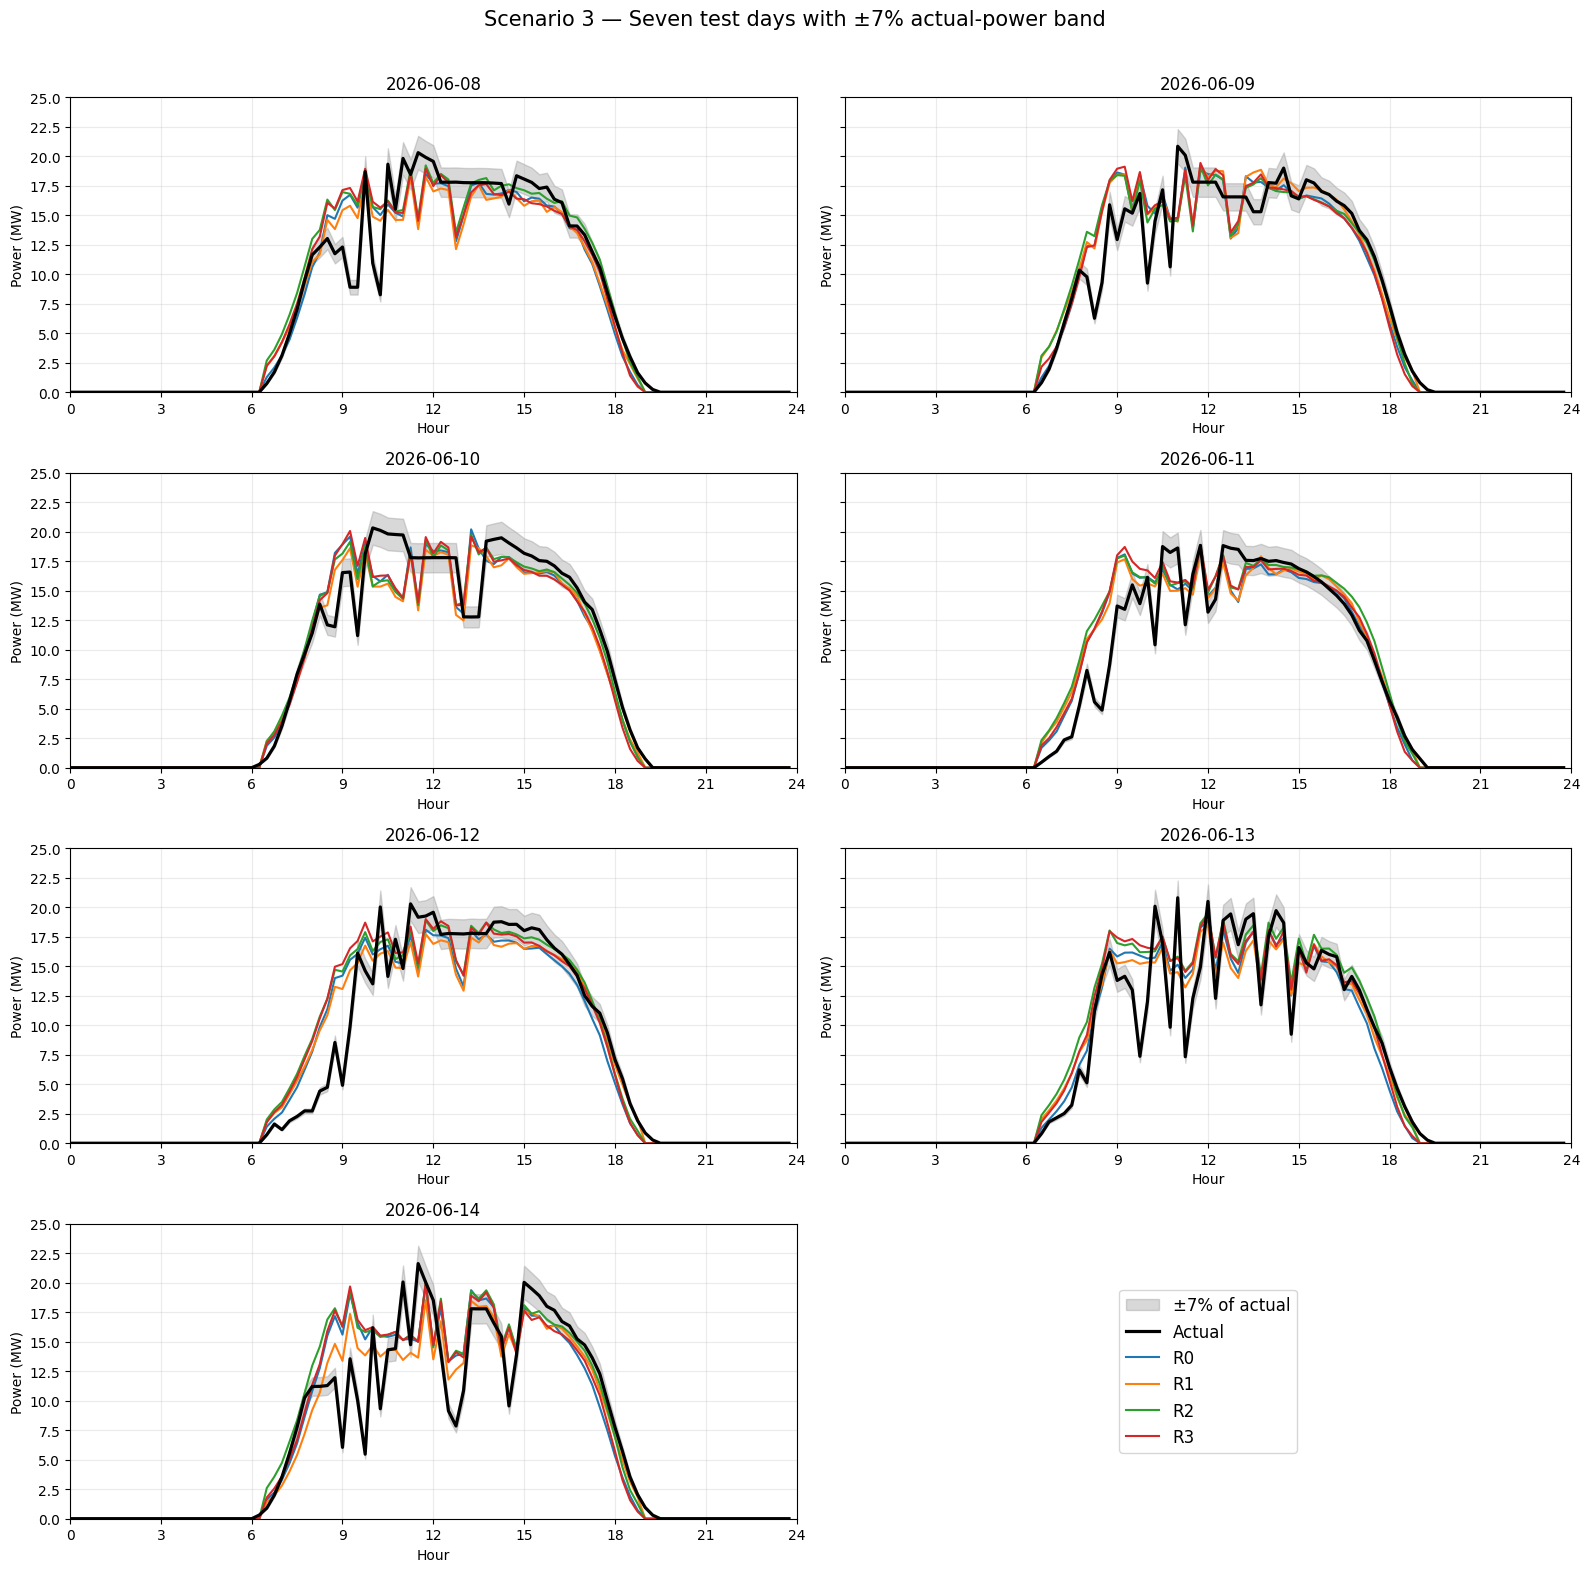

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BAND_FRACTION = 0.07
ACTIVE_THRESHOLD_MW = 0.1

# 1. Predict using the loaded model.
predictions_scaled = model.predict(
    [X_test_scaled, X_future_test_selected],
    verbose=0,
)

y_test_pred_raw = scaler.inverse_transform(
    predictions_scaled.reshape(-1, 1)
).reshape(y_test.shape)

# Apply the same postprocessing used during feature selection.
y_test_pred = np.maximum(y_test_pred_raw, 0.0)
y_test_pred[:, night_blocks] = 0.0

assert np.isfinite(y_test_pred).all()

test_dates_array = np.asarray(dates_test)
test_labels = np.asarray(revision_labels_test)
unique_test_dates = sorted(set(test_dates_array))

assert len(unique_test_dates) == 7, "Expected seven test days."
assert y_test_pred.shape == (7 * len(REVISION_LENGTHS), TARGET_LENGTH)

for day in unique_test_dates:
    for revision in REVISION_LENGTHS:
        count = np.sum(
            (test_dates_array == day) & (test_labels == revision)
        )
        assert count == 1, f"Missing/duplicate sample: {day}, {revision}"

print("Forecast target dates:", ", ".join(map(str, unique_test_dates)))
print("7 test days × 4 revisions = 28 profiles, each with 96 blocks.")


# 2. Metrics and counts inside ±7% of actual power.
rows = []

for revision in ["Overall", *REVISION_LENGTHS]:
    mask = (
        np.ones(len(y_test), dtype=bool)
        if revision == "Overall"
        else test_labels == revision
    )

    actual = y_test[mask].ravel()
    predicted = y_test_pred[mask].ravel()

    tolerance = BAND_FRACTION * np.abs(actual)
    inside = np.abs(predicted - actual) <= tolerance + 1e-6
    active = actual > ACTIVE_THRESHOLD_MW

    rows.append({
        "Revision": revision,
        "MAE (MW)": mean_absolute_error(actual, predicted),
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
        "Inside / all": f"{inside.sum()}/{inside.size}",
        "Inside all (%)": 100 * inside.mean(),
        "Inside / active": f"{(inside & active).sum()}/{active.sum()}",
        "Inside active (%)": (
            100 * inside[active].mean() if active.any() else np.nan
        ),
    })

test_metrics = pd.DataFrame(rows)
print("\n", test_metrics.round(4).to_string(index=False))


# 3. Plot all seven days with a shaded ±7% band.
hours = np.arange(TARGET_LENGTH) / 4
colors = {
    "R0": "tab:blue",
    "R1": "tab:orange",
    "R2": "tab:green",
    "R3": "tab:red",
}

fig, axes = plt.subplots(
    4, 2, figsize=(16, 16), sharex=True, sharey=True
)
axes = axes.ravel()

# Include the upper band when setting plot limits.
maximum = max(
    float(np.max(y_test + BAND_FRACTION * np.abs(y_test))),
    float(y_test_pred.max()),
)
y_upper = max(20.0, np.ceil(maximum / 2.5) * 2.5)

for ax, day in zip(axes, unique_test_dates):
    day_indices = np.flatnonzero(test_dates_array == day)
    actual = y_test[day_indices[0]]

    assert np.allclose(y_test[day_indices], actual[None, :])

    tolerance = BAND_FRACTION * np.abs(actual)
    lower_band = actual - tolerance
    upper_band = actual + tolerance

    ax.fill_between(
        hours,
        lower_band,
        upper_band,
        color="gray",
        alpha=0.30,
        label="±7% of actual",
        zorder=1,
    )

    ax.plot(
        hours, actual,
        color="black",
        linewidth=2.3,
        label="Actual",
        zorder=3,
    )

    for revision in REVISION_LENGTHS:
        index = np.flatnonzero(
            (test_dates_array == day) & (test_labels == revision)
        )[0]

        ax.plot(
            hours, y_test_pred[index],
            color=colors[revision],
            linewidth=1.5,
            label=revision,
            zorder=2,
        )

    ax.set_title(str(day))
    ax.set_xlim(0, 24)
    ax.set_ylim(0, y_upper)
    ax.set_xticks(np.arange(0, 25, 3))
    ax.set_yticks(np.arange(0, y_upper + 0.1, 2.5))
    ax.set_xlabel("Hour")
    ax.set_ylabel("Power (MW)")
    ax.tick_params(labelbottom=True)
    ax.grid(alpha=0.25)

axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=12)

fig.suptitle(
    "Scenario 3 — Seven test days with ±7% actual-power band",
    fontsize=15,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

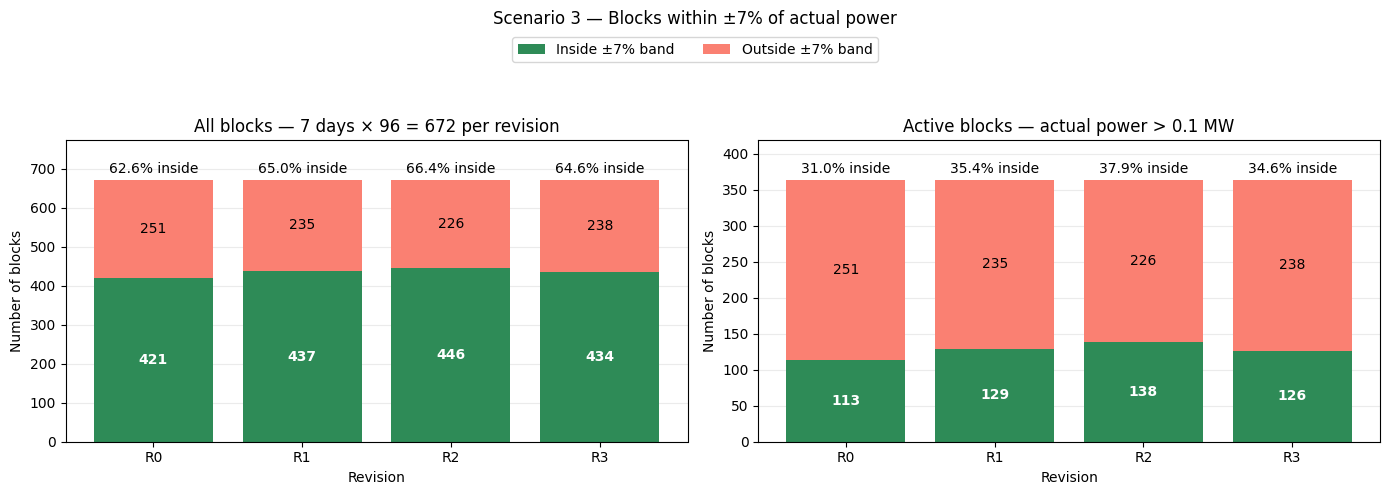

In [10]:
# Uses existing y_test, y_test_pred, and test_labels.
revisions = list(REVISION_LENGTHS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, active_only in zip(axes, [False, True]):
    inside_counts = []
    outside_counts = []

    for revision in revisions:
        revision_mask = test_labels == revision

        actual = y_test[revision_mask].ravel()
        predicted = y_test_pred[revision_mask].ravel()

        eligible = (
            actual > ACTIVE_THRESHOLD_MW
            if active_only
            else np.ones(actual.shape, dtype=bool)
        )

        inside = (
            np.abs(predicted - actual)
            <= BAND_FRACTION * np.abs(actual) + 1e-6
        )

        inside_counts.append(int(np.sum(inside & eligible)))
        outside_counts.append(int(np.sum(~inside & eligible)))

    inside_counts = np.asarray(inside_counts)
    outside_counts = np.asarray(outside_counts)
    totals = inside_counts + outside_counts

    ax.bar(
        revisions, inside_counts,
        color="seagreen", label="Inside ±7% band",
    )
    ax.bar(
        revisions, outside_counts,
        bottom=inside_counts,
        color="salmon", label="Outside ±7% band",
    )

    for i, (inside, outside, total) in enumerate(
        zip(inside_counts, outside_counts, totals)
    ):
        if inside:
            ax.text(
                i, inside / 2, str(inside),
                ha="center", va="center", color="white",
                fontweight="bold",
            )
        if outside:
            ax.text(
                i, inside + outside / 2, str(outside),
                ha="center", va="center",
            )
        if total:
            ax.text(
                i, total + max(totals.max(), 1) * 0.025,
                f"{100 * inside / total:.1f}% inside",
                ha="center", fontsize=10,
            )

    ax.set_title(
        "Active blocks — actual power > 0.1 MW"
        if active_only else
        "All blocks — 7 days × 96 = 672 per revision"
    )
    ax.set_xlabel("Revision")
    ax.set_ylabel("Number of blocks")
    ax.set_ylim(0, max(int(totals.max()), 1) * 1.15)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center",
    bbox_to_anchor=(0.5, 0.94), ncol=2,
)
fig.suptitle("Scenario 3 — Blocks within ±7% of actual power")
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd

SEASON = "Summer"
scenario = "S3"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
prediction_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Predictions"
)
prediction_dir.mkdir(parents=True, exist_ok=True)

results_path = prediction_dir / f"{SEASON}_Daily_RNN_{scenario}.csv"

# 1. Verify all seven target days and four revisions.
dates = pd.DatetimeIndex(pd.to_datetime(dates_test)).normalize()
labels = np.asarray(revision_labels_test)

revision_names = {
    "R0": "Rev0",
    "R1": "Rev1",
    "R2": "Rev2",
    "R3": "Rev3",
}
test_days = pd.date_range("2026-06-08", "2026-06-14", freq="D")

expected = pd.MultiIndex.from_product(
    [test_days, list(revision_names)]
)
observed = pd.MultiIndex.from_arrays([dates, labels])

if not observed.sort_values().equals(expected.sort_values()):
    raise ValueError(
        "Expected exactly one R0–R3 forecast per day for June 8–14."
    )

# 2. Predict using the trained Summer S3 model.
predicted_scaled = benchmark_model.predict(
    [X_test_scaled, benchmark_future_test],
    batch_size=16,
    verbose=0,
)

y_actual = np.asarray(y_test, dtype=np.float64).copy()

if predicted_scaled.shape != (28, 96) or y_actual.shape != (28, 96):
    raise ValueError("Expected actual and forecast shapes of (28, 96).")

y_test_pred_raw = scaler.inverse_transform(
    predicted_scaled.reshape(-1, 1)
).reshape(28, 96)

if not (
    np.isfinite(y_actual).all()
    and np.isfinite(y_test_pred_raw).all()
):
    raise ValueError("Actual or forecast power contains nonfinite values.")

# 3. Use the complete summer training profiles from sample creation.
training_profiles = np.asarray(
    nightmask_training_power, dtype=np.float64
)

if (
    training_profiles.ndim != 2
    or training_profiles.shape[0] == 0
    or training_profiles.shape[1] != BLOCKS_PER_DAY
    or not np.isfinite(training_profiles).all()
):
    raise ValueError("Invalid training profiles for the night mask.")

active_fraction = (training_profiles > 0.1).mean(axis=0)
night_mask = active_fraction < 0.10
night_blocks = np.flatnonzero(night_mask)

y_test_pred = np.maximum(y_test_pred_raw, 0.0)
y_test_pred[:, night_mask] = 0.0

# Compatibility with later metrics and plotting cells.
y_pred_raw = y_test_pred_raw
y_pred = y_test_pred

# Verify that actual targets agree across revisions.
for day in test_days:
    day_actual = y_actual[dates == day]
    if not np.allclose(
        day_actual, day_actual[0], atol=1e-6, rtol=0.0
    ):
        raise ValueError(f"{day.date()}: actuals differ across revisions.")

# 4. Export the same four columns as S1 and S2.
block_offsets = pd.to_timedelta(15 * np.arange(96), unit="min")

predictions_df = pd.DataFrame({
    "Revision": np.repeat(
        [revision_names[r] for r in labels], 96
    ),
    "Target_Time": (
        dates.repeat(96)
        + np.tile(block_offsets.to_numpy(), len(dates))
    ),
    "Actual_MW": y_actual.ravel(),
    "Forecast_MW": y_test_pred.ravel(),
}).sort_values(
    ["Revision", "Target_Time"],
    ignore_index=True,
)

predictions_df.to_csv(
    results_path,
    index=False,
    date_format="%Y-%m-%d %H:%M",
)

print(f"Saved {len(predictions_df):,} rows to:")
print(results_path)

Saved 2,688 rows to:
C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Summer\Predictions\Summer_Daily_RNN_S3.csv
